In [1]:
URL = "https://data.seattle.gov/api/views/65db-xm6k/rows.csv?accessType=DOWNLOAD"

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# on a déja le fichier en local
local_file = "data/fremont.csv"

Chargement

In [4]:
# version naïve
data = pd.read_csv(local_file)
data.shape

(175200, 4)

In [5]:
data.head()

,Date,Fremont Bridge Total,Fremont Bridge East Sidewalk,Fremont Bridge West Sidewalk
0,08/01/2022 12:00:00 AM,23.0,7.0,16.0
1,08/01/2022 01:00:00 AM,12.0,5.0,7.0
2,08/01/2022 02:00:00 AM,3.0,0.0,3.0
3,08/01/2022 03:00:00 AM,5.0,2.0,3.0
4,08/01/2022 04:00:00 AM,10.0,2.0,8.0


In [5]:
#Exercice
data.drop_duplicates(inplace=True)
#on affiche la nouvelle taille
data.shape

(87600, 4)

Echauffement: le DatetimeIndex

In [7]:
sample_dates = pd.to_datetime([
    "2024-01-15 08:00:00",
    "2024-01-20 17:30:00",
    "2024-02-03 12:00:00",
])

In [8]:
#1.
type(sample_dates)

pandas.DatetimeIndex

In [9]:
#2.
#sample_dates.date retourne les jours correspondant à chacun des éléments de sample_dates
sample_dates.date

array([datetime.date(2024, 1, 15), datetime.date(2024, 1, 20),
       datetime.date(2024, 2, 3)], dtype=object)

In [10]:
#sample_dates.time retourne les heures (et les minutes) correspondants à chacun des éléments de samples_dates
sample_dates.time

array([datetime.time(8, 0), datetime.time(17, 30), datetime.time(12, 0)],
      dtype=object)

In [11]:
#sample_dates.dayofweek retourne le numéro correspondant au jour de la semaine
sample_dates.dayofweek

Index([0, 5, 5], dtype='int32')

In [12]:
#3.
sample_dates[(sample_dates>"2024-01-20 00:00:00")]

DatetimeIndex(['2024-01-20 17:30:00', '2024-02-03 12:00:00'], dtype='datetime64[us]', freq=None)

In [13]:
#4.
sample_dates[(sample_dates.month==1)]

DatetimeIndex(['2024-01-15 08:00:00', '2024-01-20 17:30:00'], dtype='datetime64[us]', freq=None)

Parser les dates

In [14]:
# intéressant aussi, pour voir notamment les points manquants
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 87600 entries, 0 to 87599
Data columns (total 4 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Date                          87600 non-null  str    
 1   Fremont Bridge Total          87586 non-null  float64
 2   Fremont Bridge East Sidewalk  87586 non-null  float64
 3   Fremont Bridge West Sidewalk  87586 non-null  float64
dtypes: float64(3), str(1)
memory usage: 2.7 MB


In [15]:
data.dtypes

Date                                str
Fremont Bridge Total            float64
Fremont Bridge East Sidewalk    float64
Fremont Bridge West Sidewalk    float64
dtype: object

In [6]:
#Exercice
data.index=pd.to_datetime(data.Date, format="%m/%d/%Y %I:%M:%S %p")
#On supprime la colonne inutile
del data["Date"]

Renommons les colonnes

In [7]:
data.columns = ['Total', 'West', 'East']

Données manquantes et extension types

In [18]:
data.head()

,Total,West,East
Date,,,
2022-08-01 00:00:00,23.0,7.0,16.0
2022-08-01 01:00:00,12.0,5.0,7.0
2022-08-01 02:00:00,3.0,0.0,3.0
2022-08-01 03:00:00,5.0,2.0,3.0
2022-08-01 04:00:00,10.0,2.0,8.0


In [8]:
#Exercice
#1.
data[(data['Total'].isna())]

,Total,West,East
Date,,,
2013-03-10 02:00:00,NaN,NaN,NaN
2013-06-14 09:00:00,NaN,NaN,NaN
2013-06-14 10:00:00,NaN,NaN,NaN
2014-03-09 02:00:00,NaN,NaN,NaN
2015-03-08 02:00:00,NaN,NaN,NaN
2015-04-21 11:00:00,NaN,NaN,NaN
2015-04-21 12:00:00,NaN,NaN,NaN
2016-03-13 02:00:00,NaN,NaN,NaN
2017-03-12 02:00:00,NaN,NaN,NaN


In [9]:
data[(data['Total'].isna())]=0

In [21]:
#on vérifie
data[(data['Total'].isna())]

,Total,West,East
Date,,,


A quoi ça ressemble

In [10]:
sns.set(rc={'figure.figsize':(12,4)})

<Axes: xlabel='Date'>

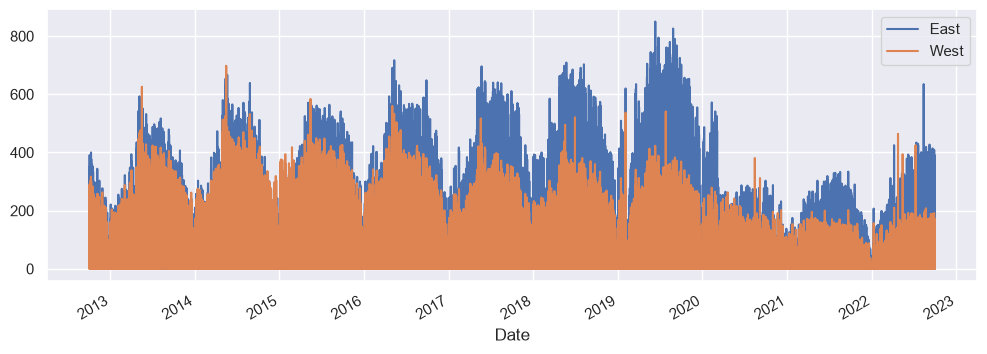

In [11]:
# un premier jet, pas terrible du tout
data[['East', 'West']].plot()

Resample(): changer la fréquence temporelle

<Axes: xlabel='Date'>

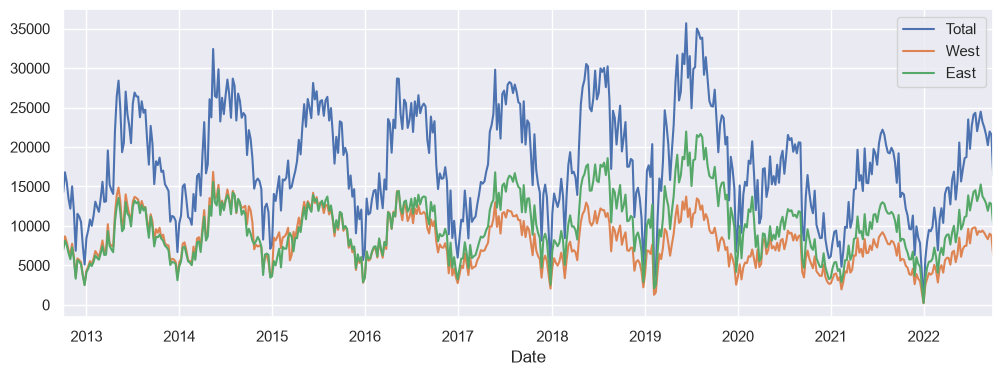

In [ ]:
#Exercice
#1.
(data.resample("1W").sum()).plot()

In [ ]:
data.resample("1W").sum().shape

(522, 3)

#2.On a bien 522*7*24=87696 donc pas loin de 87600

Découpage temporel

In [ ]:
#Exercice
data[(data.index.year<=2017)]

,Total,West,East
Date,,,
2012-10-03 00:00:00,13.0,4.0,9.0
2012-10-03 01:00:00,10.0,4.0,6.0
2012-10-03 02:00:00,2.0,1.0,1.0
2012-10-03 03:00:00,5.0,2.0,3.0
2012-10-03 04:00:00,7.0,6.0,1.0
...,...,...,...
2017-12-31 19:00:00,21.0,9.0,12.0
2017-12-31 20:00:00,14.0,6.0,8.0
2017-12-31 21:00:00,13.0,3.0,10.0


Evolution annuelle

<Axes: xlabel='Date'>

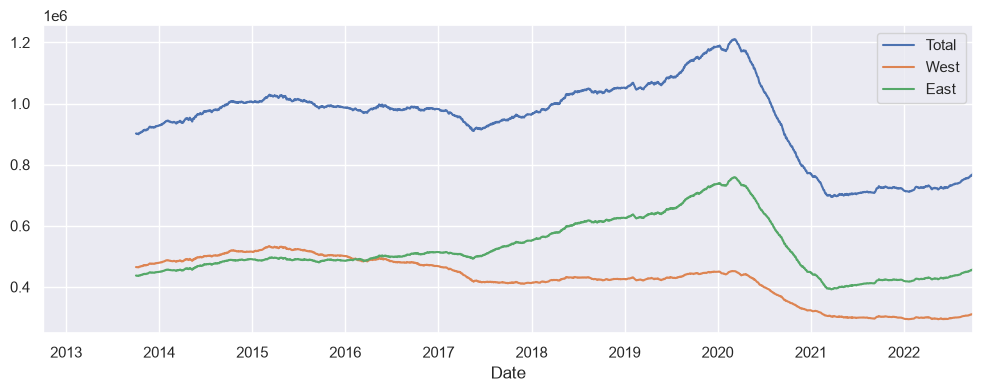

In [ ]:
#Exercice
(data.resample("1D").sum()).rolling(365).sum().plot()

Profil journalier moyen

<Axes: xlabel='time'>

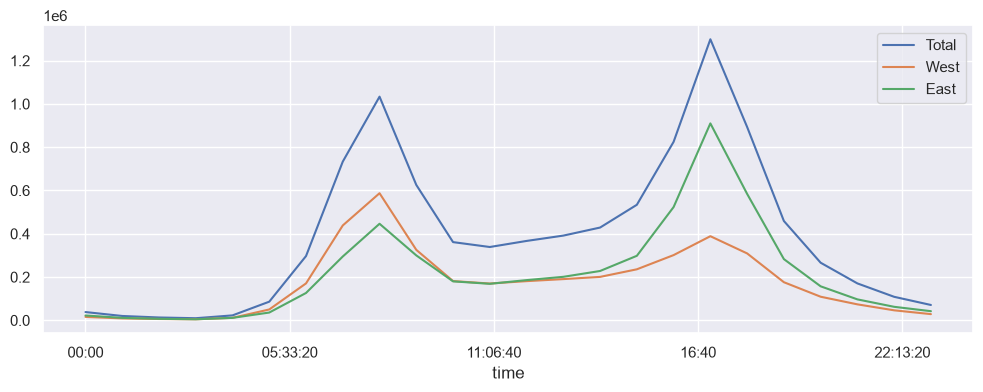

In [ ]:
#Exercice
data.groupby(data.index.time).sum().plot()

Une courbe par jour: la pivot_table

In [54]:
#Exercice
pivoted=data.pivot_table("Total",index=data.index.time,columns=data.index.date)
print(pivoted)

          2012-10-03  2012-10-04  2012-10-05  2012-10-06  2012-10-07  \
00:00:00        13.0        18.0        11.0        15.0        11.0   
01:00:00        10.0         3.0         8.0        15.0        17.0   
02:00:00         2.0         9.0         7.0         9.0         3.0   
03:00:00         5.0         3.0         4.0         3.0         6.0   
04:00:00         7.0         8.0         9.0         5.0         3.0   
05:00:00        31.0        26.0        25.0         5.0         9.0   
06:00:00       155.0       142.0       105.0        27.0        17.0   
07:00:00       352.0       319.0       319.0        33.0        26.0   
08:00:00       437.0       418.0       370.0       105.0        69.0   
09:00:00       276.0       241.0       212.0       114.0       103.0   
10:00:00       118.0       120.0       119.0       115.0       108.0   
11:00:00        42.0       108.0       104.0       124.0       165.0   
12:00:00        76.0       104.0       101.0       164.0       1

<Axes: xlabel='time'>

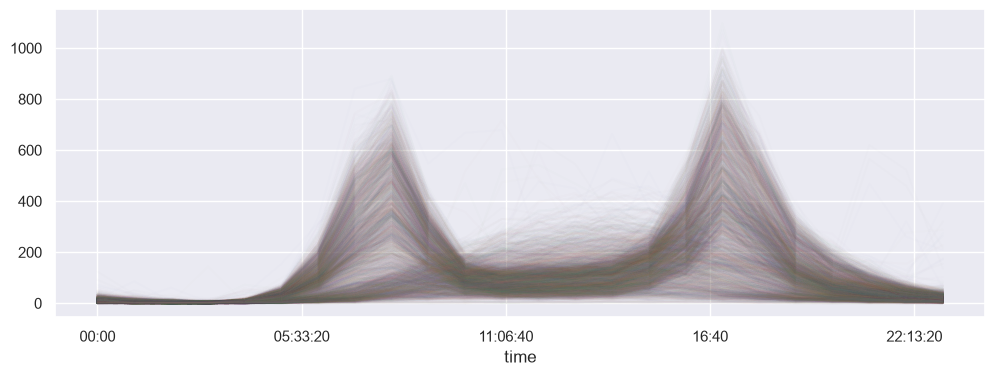

In [ ]:
#Exercice
pivoted.plot(legend=False,alpha=0.01)

Classification des jours

In [13]:
pca_input=pivoted.T.fillna(0)
print(pca_input)

            00:00:00  01:00:00  02:00:00  03:00:00  04:00:00  05:00:00  \
2012-10-03      13.0      10.0       2.0       5.0       7.0      31.0   
2012-10-04      18.0       3.0       9.0       3.0       8.0      26.0   
2012-10-05      11.0       8.0       7.0       4.0       9.0      25.0   
2012-10-06      15.0      15.0       9.0       3.0       5.0       5.0   
2012-10-07      11.0      17.0       3.0       6.0       3.0       9.0   
...              ...       ...       ...       ...       ...       ...   
2022-09-26       5.0       7.0       5.0       2.0       8.0      29.0   
2022-09-27       9.0       2.0       1.0       3.0      11.0      29.0   
2022-09-28       6.0       2.0       1.0       2.0       9.0      23.0   
2022-09-29      16.0       1.0       3.0       3.0      11.0      21.0   
2022-09-30      12.0       5.0       5.0       0.0       5.0      26.0   

            06:00:00  07:00:00  08:00:00  09:00:00  ...  14:00:00  15:00:00  \
2012-10-03     155.0     352.0  

ACP

In [14]:
from sklearn.decomposition import PCA

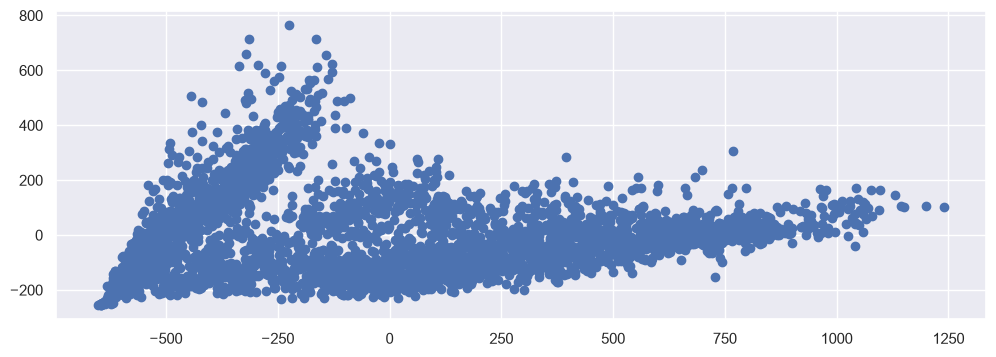

In [22]:
#Exercice
nuage=PCA(n_components=2).fit_transform(pca_input)
plt.scatter(nuage[:,0],nuage[:,1])
plt.show()

GaussianMixture

In [23]:
from sklearn.mixture import GaussianMixture


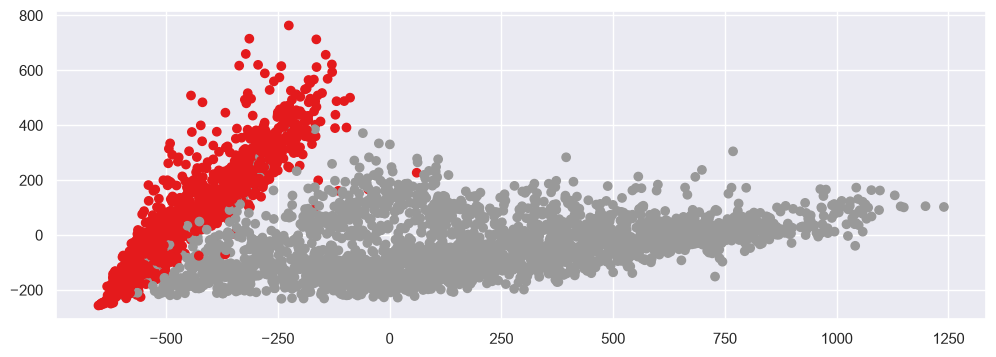

In [25]:
#Exercice
groupes=GaussianMixture(n_components=2).fit_predict(pca_input)
plt.scatter(nuage[:,0],nuage[:,1],c=groupes,cmap='Set1')
plt.show()

comparons chaque famille aux profils journaliers

<Axes: xlabel='time'>

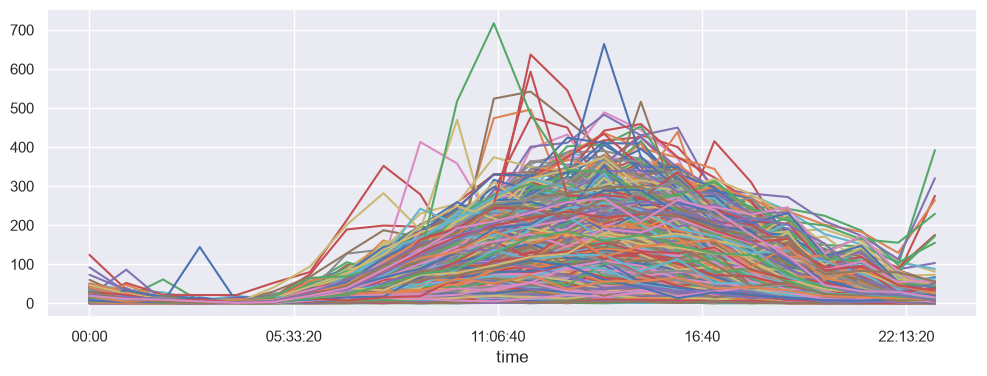

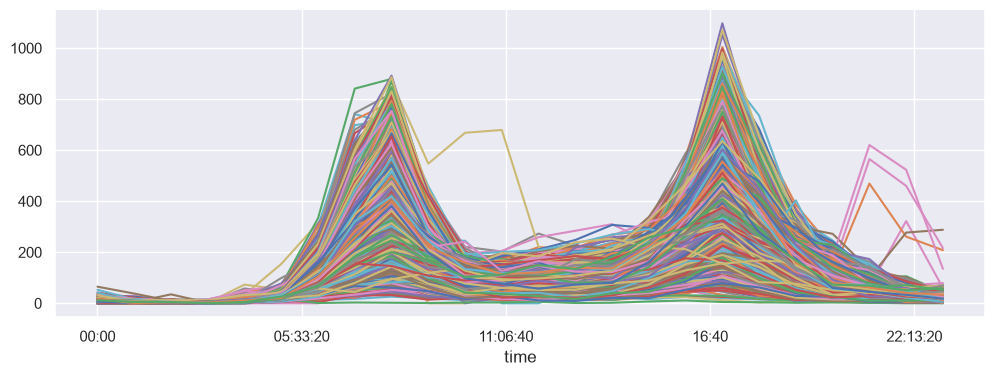

In [28]:
#Exercice
pivoted.loc[:,groupes==0].plot(legend=False)
pivoted.loc[:,groupes==1].plot(legend=False)

On distingue dans le premier graphique une grosse bosse tandis que dans le 2e les 2 bosses vues précédemment

vérifions avec le jour de la semaine

In [60]:
pivoted.columns = pd.DatetimeIndex(pivoted.columns)
pivoted.loc[(pivoted.columns.dayofweek==0)].plot()

IndexError: Boolean index has wrong length: 3650 instead of 24

Je n'ai malheureurement pas réussi à faire cette question ainsi que la dernière, je suis resté bloqué dessus